# Продажи автомобилей в Казахстане за 2019 год

## Очистка данных и анализ позиции «Меркур Авто»

## 1. Загрузка и первоначальная проверка

Подключим библиотеки и укажем путь к исходному файлу.

In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Загрузка CSV

In [4]:
raw = pd.read_csv('autokz2019.csv', sep=';', dtype='string', encoding='utf-8-sig')
print('Размер исходной таблицы:', raw.shape)

Размер исходной таблицы: (39966, 25)


In [5]:
raw.head(3)

,Год,Месяц,Компания,Бренд,Модель,Модификация,Год выпуска,Страна-производитель,Вид топлива,"Объём двиг, л,",...,Тип клиента,Форма расчета,Количество,"Цена, USD","Продажа, USD",Область,Сегментация 2013,Класс 2013,Сегментация Eng,Локализация производства
0,2019,Май,Mercur Auto,Audi,A3,TFSI,2018,Германия,Бензин,"1,4",...,Физ. Лицо,безналичный,1,28115,28115,г.Алматы,Легковые автомобили,C класс,C,Импорт
1,2019,Август,Mercur Auto,Audi,A3,TFSI,2018,Германия,Бензин,"1,4",...,Юр. Лицо,наличный,1,"32246,99","32246,99",г.Алматы,Легковые автомобили,C класс,C,Импорт
2,2019,Апрель,Mercur Auto,Audi,A4,TFSI,2018,Германия,Бензин,"1,4",...,Физ. Лицо,безналичный,1,32000,32000,г.Алматы,Легковые автомобили,D класс,D,Импорт


### Типы, пропуски и повторяющиеся строки

In [6]:
pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum(), 'missing_%': raw.isna().mean().mul(100).round(2), 'unique': raw.nunique(dropna=True)})

,dtype,missing,missing_%,unique
Год,string,0,0.00,1
Месяц,string,0,0.00,9
Компания,string,0,0.00,40
Бренд,string,0,0.00,46
Модель,string,0,0.00,273
Модификация,string,3591,8.99,1383
Год выпуска,string,501,1.25,9
Страна-производитель,string,0,0.00,19
Вид топлива,string,3140,7.86,10
"Объём двиг, л,",string,4258,10.65,114


In [7]:
print('Полные дубликаты в исходнике:', raw.duplicated().sum())
print('Полностью пустые строки:', raw.isna().all(axis=1).sum())

Полные дубликаты в исходнике: 18698
Полностью пустые строки: 0


## 2. Удаление лишних данных

Из таблицы убираем неиспользуемые поля и строки, в которых нет ни одного значения. Столбец с названием дилерского центра оставляем: он пригодится для возможного дальнейшего анализа.

In [8]:
DROP_COLUMNS = ['Модификация', 'Сегмент', 'Тип клиента', 'Форма расчета', 'Локализация производства', 'Сегментация Eng']

### Переименование столбцов

Используем английские названия для дальнейшей обработки.

In [9]:
COLUMN_MAP = {
    'Год': 'year', 'Месяц': 'month', 'Компания': 'company',
    'Бренд': 'brand', 'Модель': 'model', 'Год выпуска': 'production_year',
    'Страна-производитель': 'production_country', 'Вид топлива': 'fuel_type',
    'Объём двиг, л,': 'engine_volume_l', 'Коробка передач': 'transmission',
    'Тип привода': 'drive_type', 'Регион': 'region',
    'Наименование дилерского центра': 'dealer_center', 'Количество': 'quantity',
    'Цена, USD': 'unit_price_usd', 'Продажа, USD': 'total_sales_usd',
    'Область': 'oblast', 'Сегментация 2013': 'segment_2013',
    'Класс 2013': 'class_2013'
}

### Пробелы, пустые строки и явные дубли

In [10]:
base = raw.dropna(how='all').drop(columns=DROP_COLUMNS, errors='ignore').rename(columns=COLUMN_MAP)
for c in base.select_dtypes('string').columns:
    base[c] = base[c].str.replace(r'[\u00A0\u202F]', ' ', regex=True).str.strip().str.replace(r'\s+', ' ', regex=True)
print('До удаления повторов:',len(base),'| Дубликатов:',base.duplicated().sum())
clean = base.drop_duplicates().copy().reset_index(drop=True)

До удаления повторов: 39966 | Дубликатов: 21987


**Ограничение дедупликации.** У записей нет уникального ID сделки. Полные совпадения могут быть не только техническими дублями, но и отдельными продажами одинаковых автомобилей. Для учебного задания повторы удаляем; в реальной базе потребовалась бы сверка с системой учета.

## 3. Стандартизация категорий

### Страны производства

Используем трехбуквенные коды ISO Alpha-3. Если появится незнакомая страна, проверка сообщит, что словарь нужно дополнить.

In [12]:
COUNTRIES = {
 'Республика Казахстан':'KAZ','Российская Федерация':'RUS','Япония':'JPN',
 'Турция':'TUR','Таиланд':'THA','США':'USA','Германия':'DEU','UK':'GBR',
 'Китай':'CHN','Узбекистан':'UZB','Австрия':'AUT','Швеция':'SWE',
 'Корея':'KOR','Нидерланды':'NLD','Испания':'ESP','Бельгия':'BEL',
 'Польша':'POL','Венгрия':'HUN','Белоруссия':'BLR'
}
unknown_countries = set(clean['production_country'].dropna().unique()) - set(COUNTRIES)
clean['production_country'] = clean['production_country'].map(COUNTRIES).astype('string')

### Названия компаний и дилерских центров

Объединяем варианты написания одного названия. В частности, "Меркур Авто" и `Mercur Autos` приводим к `Mercur Auto`.

In [13]:
company_aliases = {
 'Mercur Autos':'Mercur Auto', 'Меркур Авто':'Mercur Auto',
 'Ravon Motors Kazakstan':'Равон Моторс Казахстан',
 'MMC RUS':'ММС Рус', 'Автокапитал':'Autokapital',
 'Каспиан Моторс':'Caspian Motors', 'Hino Motors':'Хино Моторс Казахстан'
}
clean['company'] = clean['company'].replace(company_aliases)
clean['dealer_center'] = clean['dealer_center'].str.replace(r'(?i)\bmercur autos?\b|меркур авто', 'Mercur Auto', regex=True)

### Виды топлива

Обозначения: F - бензин, D - дизель, E - электричество, HYB - гибрид. Значения, которые нельзя определить надежно, оставляем пустыми.

In [14]:
fuel = clean['fuel_type'].str.lower().str.strip()
fuel_map = {'бензин':'F','дизель':'D','электричество':'E','электро':'E','гибрид':'HYB'}
clean['fuel_type'] = fuel.map(fuel_map).astype('string')
print('Некорректное топливо (строк):', (fuel.notna() & clean['fuel_type'].isna()).sum())

Некорректное топливо (строк): 25


### Тип привода

AWD, 4WD и другие обозначения полного привода объединяем. Для 2WD не определяем расположение ведущей оси без дополнительных данных.

In [15]:
def norm_drive(v):
    if pd.isna(v): return pd.NA
    s = str(v).upper().replace('Х','X').replace(' ','').strip()
    if s in {'4WD','AWD','4X4','ПОЛНЫЙ','QUATTRO','4MOTION'}: return '4WD'
    if s in {'FF','FWD','ПЕРЕДНИЙ','ПЕРЕДНИЙ(FF)'}: return 'FWD'
    if s in {'RWD','ЗАДНИЙ'}: return 'RWD'
    if s in {'2WD','4X2','4X2.2'}: return '2WD'
    return pd.NA

In [16]:
clean['drive_type'] = clean['drive_type'].map(norm_drive).astype('string')

### Коробка передач

Приводим обозначения к двум категориям: «Автомат» и «Механика». Роботизированные коробки и вариаторы относим к автоматическим.

In [17]:
def norm_transmission(v):
    if pd.isna(v): return pd.NA
    s = str(v).upper().replace('А','A').replace('Т','T').replace('М','M').replace(' ','')
    if s in {'0','#Н/Д','ПЕРЕДНИЙ','4WD','TDI','8'}: return pd.NA
    if 'CVT' in s or 'ВАРИ' in s or 'VARI' in s: return 'Автомат'
    if any(x in s for x in ['DSG','DCT','PDK','TRONIC','TIPTRONIC','STEPTRONIC','POWERSHIFT','S-TRONIC']): return 'Автомат'
    if 'АКП' in s or 'AT' in s or s.endswith('A') or s in {'РЕДУКТОР'}: return 'Автомат'
    if 'МКП' in s or 'MT' in s or s.endswith('M') or 'МЕХ' in s: return 'Механика'
    return pd.NA

In [18]:

clean['transmission'] = clean['transmission'].map(norm_transmission).astype('string')

### Регион и область

Приводим названия к единому регистру и проверяем распределение категорий после очистки.

In [19]:
for c in ['region','oblast']:
    clean[c] = clean[c].str.title()
print('Виды привода:', clean['drive_type'].value_counts(dropna=False).to_dict())
print('Трансмиссии:', clean['transmission'].value_counts(dropna=False).to_dict())

Виды привода: {'4WD': 7690, 'FWD': 4264, '2WD': 3423, <NA>: 1527, 'RWD': 1075}
Трансмиссии: {'Автомат': 11235, 'Механика': 3847, <NA>: 2897}


## 4. Числовые значения, дата и аномалии

### Числовые столбцы

Убираем пробелы внутри чисел, меняем десятичную запятую на точку и переводим значения в числовой тип.

In [20]:
def parse_numeric(series):
    return pd.to_numeric(series.astype('string').str.replace(r'[\u00a0\u202f\s]', '', regex=True).str.replace(',', '.', regex=False), errors='coerce')

for col in ['quantity','unit_price_usd','total_sales_usd','production_year','year']:
    clean[col] = parse_numeric(clean[col])

### Дата продажи

По году и месяцу создаем дату последнего дня месяца. Первоначальные столбцы удаляем.

In [21]:
MONTHS = {'январь':1,'февраль':2,'март':3,'апрель':4,'май':5,'июнь':6,'июль':7,'август':8,'сентябрь':9,'октябрь':10,'ноябрь':11,'декабрь':12}
month_n = clean['month'].str.lower().map(MONTHS)
clean['sale_date'] = (pd.to_datetime({'year':clean['year'].astype('Int64'), 'month':month_n.astype('Int64'), 'day':1}, errors='coerce') + pd.offsets.MonthEnd(0))
clean = clean.drop(columns=['year','month'])

### Объем двигателя

Извлекаем число из строки и исправляем очевидные ошибки Chevrolet Niva на основании модели. Значения мощности двигателя и емкости батареи не считаем объемом. Для электромобилей поле остается пустым.

In [22]:
engine_raw = clean['engine_volume_l'].str.upper().str.replace(',', '.', regex=False)
engine_number = pd.to_numeric(engine_raw.str.extract(r'(\d+(?:\.\d+)?)', expand=False), errors='coerce')
engine_number = engine_number.mask(engine_raw.str.contains(r'Л\.?\s*С\.?|KWH', case=False, na=False))
niva_mask = (clean['brand'].str.lower().eq('chevrolet') & clean['model'].str.lower().eq('niva'))
niva_bad = niva_mask & engine_number.gt(2)
engine_number = engine_number.mask(niva_bad, 1.7)
electric = clean['fuel_type'].eq('E').fillna(False)
engine_number = engine_number.mask(electric)
engine_number = engine_number.mask(engine_number.le(0) | engine_number.gt(15))
clean['engine_volume_l'] = engine_number.astype('Float64')

### Итоговые числовые типы

Количество и год выпуска храним как целые числа, цены и сумму продажи - как дробные.

In [23]:
for c in ['quantity','production_year']:
    clean[c] = clean[c].astype('Int64')
for c in ['unit_price_usd','total_sales_usd']:
    clean[c] = clean[c].astype('Float64')

### Возвраты, оптовые операции и расхождения в суммах

Отрицательные количества не удаляем: это могут быть возвраты. Несколько автомобилей в одной строке также допустимы. Подозрительные суммы отмечаем отдельным признаком, не заменяя их выдуманными значениями.

In [24]:
clean['is_return'] = (clean['quantity'].lt(0) | clean['total_sales_usd'].lt(0)).fillna(False)
clean['is_bulk'] = clean['quantity'].gt(1).fillna(False)
expected = clean['quantity'] * clean['unit_price_usd']
clean['amount_mismatch'] = ((clean['total_sales_usd']-expected).abs() > (1 + expected.abs()*0.01)).fillna(False)

In [25]:
print('Исправлено объемов Chevrolet Niva:',int(niva_bad.sum()))
print('Возвратов:',int(clean['is_return'].sum()), '| оптовых строк:',int(clean['is_bulk'].sum()))
print('Несовпадений цены × количества и итога:',int(clean['amount_mismatch'].sum()))
display(clean.loc[clean['amount_mismatch'],['brand','model','quantity','unit_price_usd','total_sales_usd']].head(10))

Исправлено объемов Chevrolet Niva: 25
Возвратов: 1 | оптовых строк: 2732
Несовпадений цены × количества и итога: 0


,brand,model,quantity,unit_price_usd,total_sales_usd


### Принципы расчета показателей

Для количества автомобилей и выручки используем сумму по всем строкам с учетом возвратов. Показатель `выручка / количество` называем средней выручкой на автомобиль, поскольку строка может описывать оптовую операцию. Неопределенные характеристики сохраняются как пропуски.

## 5. Проверка качества и сохранение датасета

### Категориальные типы и проверка дат

Проверяем формат даты и стандартизацию значений. После нормализации удаляем дополнительно появившиеся полные совпадения.

In [27]:
for c in ['fuel_type','transmission','drive_type','segment_2013','class_2013']:
    clean[c] = clean[c].astype('category')
assert pd.api.types.is_datetime64_any_dtype(clean['sale_date'])
assert (clean['sale_date'].dt.is_month_end).all()
assert clean['production_country'].dropna().str.fullmatch(r'[A-Z]{3}').all()
extra_duplicates = int(clean.duplicated().sum())
print('Дополнительные дубли после нормализации:', extra_duplicates)
clean = clean.drop_duplicates().reset_index(drop=True)
assert not clean.duplicated().any()
assert clean['fuel_type'].dropna().isin(['F','D','E','HYB']).all()
assert clean['transmission'].dropna().isin(['Автомат','Механика']).all()

Дополнительные дубли после нормализации: 0


### Экспорт в CSV

In [28]:
clean.to_csv('autokz2019_cleaned.csv', sep=';', index=False, decimal=',', encoding='utf-8-sig', date_format='%Y-%m-%d')
quality = pd.DataFrame({'column':clean.columns,'dtype':clean.dtypes.astype(str).values,'missing_count':clean.isna().sum().values,'missing_pct':clean.isna().mean().mul(100).round(2).values})
quality.to_csv('data_quality_summary.csv',index=False,encoding='utf-8-sig')

## 6. Исследовательский анализ рынка

Рассмотрим распределения цен и характеристик автомобилей, лидеров продаж и динамику по месяцам.

### Распределение цены

Возвраты исключаем из распределения индивидуальных цен. Для графика ограничиваем верхний 1% цен, чтобы редкие дорогие машины не сжимали основную часть распределения.

In [29]:
sales = clean.loc[(clean['quantity'] > 0) & (clean['unit_price_usd'] > 0)].copy()

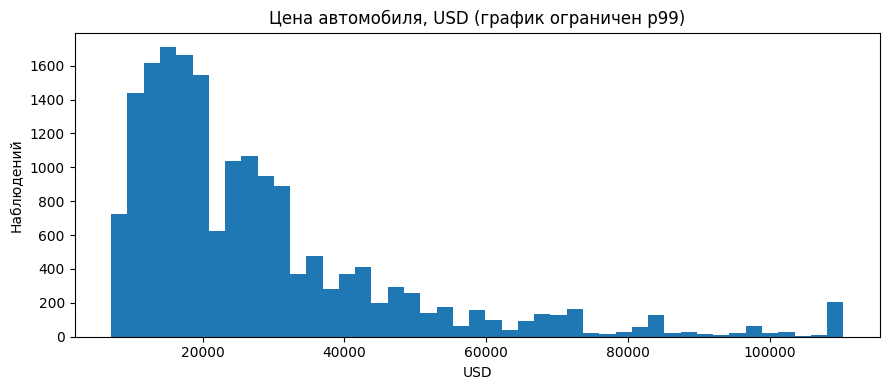

In [30]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(sales['unit_price_usd'].clip(upper=sales['unit_price_usd'].quantile(.99)).dropna().astype(float), bins=45)
ax.set(title='Цена автомобиля, USD (график ограничен p99)', xlabel='USD', ylabel='Наблюдений')
plt.tight_layout()
plt.show()

In [31]:
print('Квантили цены:');display(sales['unit_price_usd'].quantile([0,.25,.5,.75,.9,.95,.99,1]).to_frame('USD'))

Квантили цены:


,USD
0.00,7100.0
0.25,15117.10385
0.50,22093.5768
0.75,32574.077615
0.90,51800.07531
0.95,70773.68249
0.99,110364.3925
1.00,328510.9706


### Объем двигателя

Проверим, какие объемы чаще всего встречаются среди проданных автомобилей.

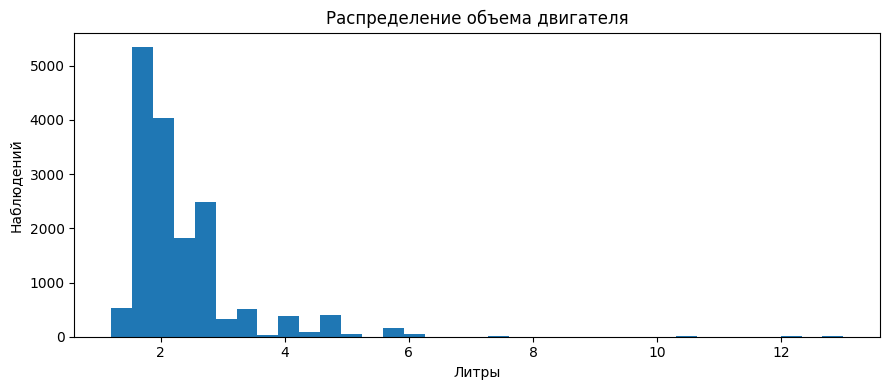

In [32]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(sales['engine_volume_l'].dropna().astype(float), bins=35)
ax.set(title='Распределение объема двигателя', xlabel='Литры', ylabel='Наблюдений')
plt.tight_layout()
plt.show()

### Год выпуска

Распределение помогает оценить долю новых и более старых автомобилей в выгрузке.

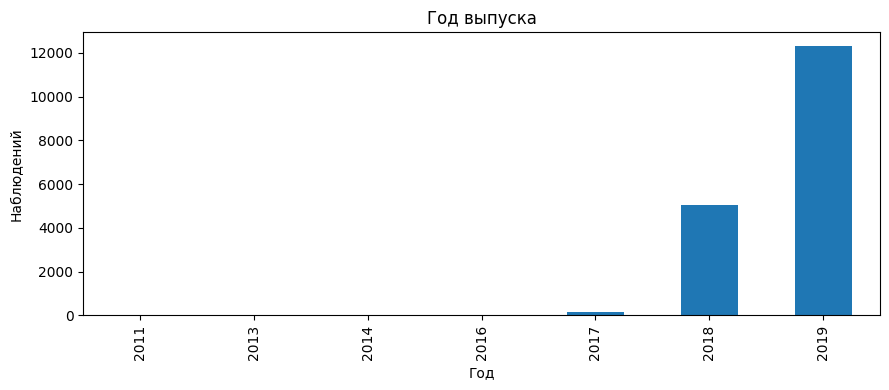

In [33]:
fig, ax = plt.subplots(figsize=(9, 4))
sales['production_year'].value_counts().sort_index().plot.bar(ax=ax)
ax.set(title='Год выпуска', xlabel='Год', ylabel='Наблюдений')
plt.tight_layout()
plt.show()

### Продажи по категориям

Группируем данные по бренду, модели, региону, типу топлива, трансмиссии, сегменту и стране производства. Количество считаем как сумму автомобилей, а не число строк.

In [34]:
def sales_by(col, frame=clean, n=12):
    res = frame.groupby(col, observed=True,dropna=False).agg(units=('quantity','sum'), revenue_usd=('total_sales_usd','sum'),rows=('quantity','size'))
    return res.sort_values('units',ascending=False).head(n)

In [35]:
for col in ['brand','model','region','fuel_type','transmission','segment_2013','production_country']:
    print('\nПродажи по:',col)
    display(sales_by(col))


Продажи по: brand


,units,revenue_usd,rows
brand,,,
Lada,10965,106302178.947374,1885
Hyundai,4012,92087198.40548,4012
Toyota,3134,128754348.66048,3134
Kia,2346,45415000.0,823
Nissan,1625,38969561.22826,1021
UAZ,1166,16108852.972269,732
GAZ,1099,19519974.51367,1099
Volkswagen,1021,21060983.4548,459
Skoda,776,19693149.5,370



Продажи по: model


,units,revenue_usd,rows
model,,,
Granta,3657,26620605.263154,456
Vesta,2579,30240973.68422,585
4x4,2469,22338600.0,251
Largus,1677,19105400.0,262
Tucson,1129,29843445.61453,1129
Rio,993,13755500.0,182
Camry,948,31891757.43281,948
Accent,913,15237844.64979,913
Creta,827,16565615.04961,827



Продажи по: region


,units,revenue_usd,rows
region,,,
Алматы,6611,203987244.449094,3857
Нур-Султан,4918,132561091.567767,3038
Атырау,2320,43765211.815759,1092
Караганда,2082,39740022.430533,1181
Шымкент,2016,39652052.25999,1151
Костанай,2012,41082293.69982,1204
Усть-Каменогорск,1748,32809747.214189,812
Уральск,1571,30165807.048232,891
Актобе,1327,29352388.317157,869


... (4 outputs left out)


Продажи по: segment_2013


,units,revenue_usd,rows
segment_2013,,,
Легковые автомобили,13722,213743888.404864,6265
Внедорожники,12677,376728321.373509,8638
Коммерческие автомобили,3070,97370033.191741,2182
Минивэны,1786,21969302.76138,366
Пикапы,340,10155238.42884,338



Продажи по: production_country


,units,revenue_usd,rows
production_country,,,
<NA>,31595,719966784.160334,17789


### Лидеры среди брендов

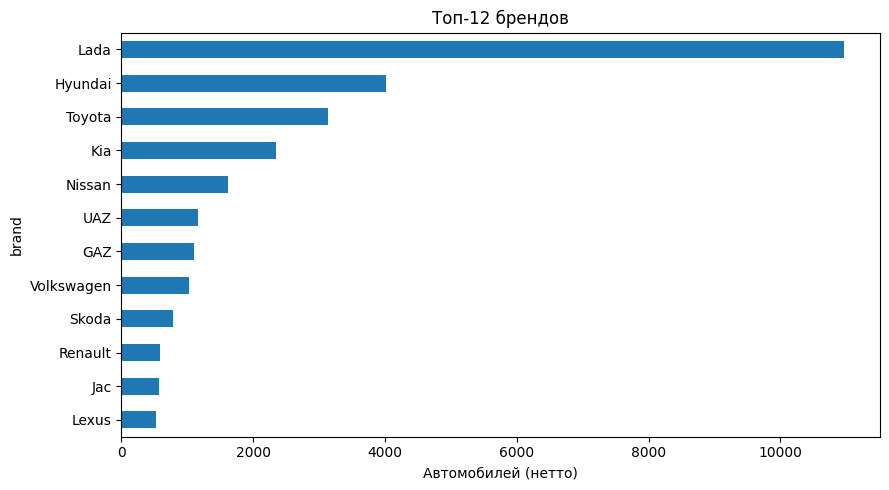

In [36]:
fig, ax = plt.subplots(figsize=(9, 5))
sales_by('brand', n=12)['units'].sort_values().plot.barh(ax=ax)
ax.set(title='Топ-12 брендов', xlabel='Автомобилей (нетто)')
plt.tight_layout()
plt.show()

### Регионы с наибольшим объемом продаж

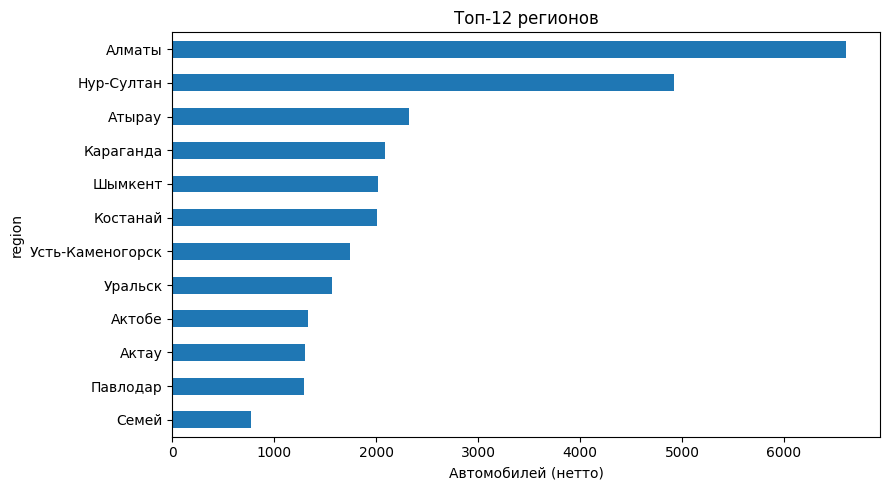

In [37]:
fig, ax = plt.subplots(figsize=(9, 5))
sales_by('region', n=12)['units'].sort_values().plot.barh(ax=ax)
ax.set(title='Топ-12 регионов', xlabel='Автомобилей (нетто)')
plt.tight_layout()
plt.show()

### Динамика по месяцам

Посмотрим на изменение количества автомобилей и средней выручки на один автомобиль. Девять месяцев не позволяют делать вывод о годовой сезонности.

In [38]:
monthly = clean.groupby('sale_date').agg(units=('quantity','sum'), revenue_usd=('total_sales_usd','sum')).sort_index()
monthly['avg_usd_per_car'] = monthly['revenue_usd']/monthly['units'].replace(0,np.nan)
display(monthly)

,units,revenue_usd,avg_usd_per_car
sale_date,,,
2019-01-31,2762,62325224.20024,22565.25134
2019-02-28,3005,64441874.845491,21444.883476
2019-03-31,3281,74688858.543214,22764.053198
2019-04-30,3980,91005663.487862,22865.744595
2019-05-31,3757,89546640.04311,23834.612734
2019-06-30,3771,87776727.95955,23276.777502
2019-07-31,3962,91312325.121409,23047.028047
2019-08-31,3772,83781344.608102,22211.385103
2019-09-30,3305,75088125.351356,22719.553813


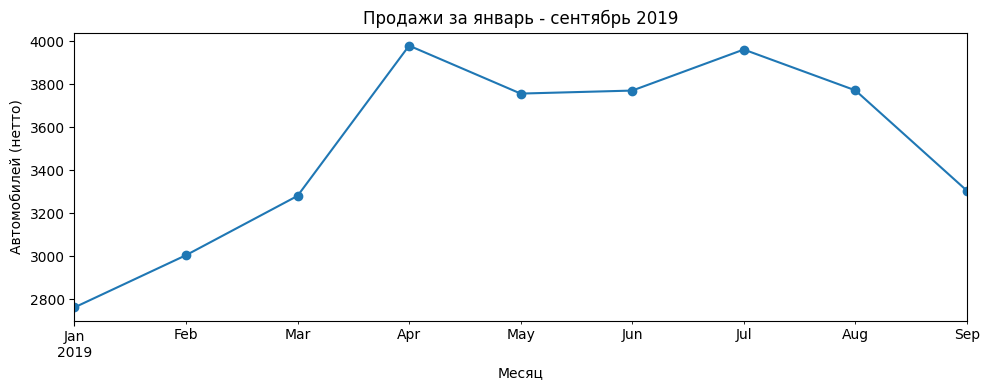

In [39]:
fig, ax = plt.subplots(figsize=(10, 4))
monthly['units'].plot(marker='o', ax=ax)
ax.set(title='Продажи за январь - сентябрь 2019', xlabel='Месяц', ylabel='Автомобилей (нетто)')
plt.tight_layout()
plt.show()

## 7. Позиция «Меркур Авто»

Сравним количество проданных автомобилей, выручку и структуру продаж компании с рынком Казахстана.

### Выборка компании и расчет основных показателей

In [40]:
IS_MERCUR = clean['company'].eq('Mercur Auto')
mercur = clean.loc[IS_MERCUR].copy()
market = clean.copy()

In [41]:
def kpi(frame):
    units=frame['quantity'].sum(); revenue=frame['total_sales_usd'].sum()
    return pd.Series({'rows':len(frame),'units':units,'revenue_usd':revenue,
                      'usd_per_car': revenue/units if units else np.nan,
                      'bulk_rows':int(frame['is_bulk'].sum()), 'return_rows':int(frame['is_return'].sum())})

In [42]:
kpis=pd.DataFrame({'Казахстан':kpi(market),'Mercur Auto':kpi(mercur)})
display(kpis)

,Казахстан,Mercur Auto
rows,1.778900e+04,3.660000e+02
units,3.159500e+04,3.730000e+02
revenue_usd,7.199668e+08,1.466684e+07
usd_per_car,2.278736e+04,3.932130e+04
bulk_rows,2.701000e+03,2.000000e+00
return_rows,1.000000e+00,0.000000e+00


### Доля рынка по объему и выручке

Сравниваем показатели компании с общими показателями очищенного датасета.

In [43]:
market_share_units = kpis.loc['units','Mercur Auto']/kpis.loc['units','Казахстан']*100
market_share_revenue = kpis.loc['revenue_usd','Mercur Auto']/kpis.loc['revenue_usd','Казахстан']*100
print(f'Доля Mercur Auto: {market_share_units:.2f}% по автомобилям, {market_share_revenue:.2f}% по выручке')

Доля Mercur Auto: 1.18% по автомобилям, 2.04% по выручке


### Доля в разрезе брендов, регионов и сегментов

In [44]:
def market_share_by(column):
    whole=market.groupby(column,dropna=False,observed=True)['quantity'].sum().rename('market_units')
    part=mercur.groupby(column,dropna=False,observed=True)['quantity'].sum().rename('mercur_units')
    result=pd.concat([whole,part],axis=1).fillna(0)
    result['share_pct']=(result['mercur_units']/result['market_units'].replace(0,np.nan)*100)
    return result.sort_values('mercur_units',ascending=False)

In [45]:
for dimension in ['brand','region','segment_2013','class_2013']:
    print('\nДоля по',dimension);display(market_share_by(dimension).head(15))


Доля по brand


,market_units,mercur_units,share_pct
brand,,,
Volkswagen,1021,275,26.934378
Porsche,52,52,100.0
Audi,46,46,100.0
ANKAI,11,0,0.0
Mazda,246,0,0.0
Mercedes-Benz,145,0,0.0
Mercedes-Benz Trucks,44,0,0.0
Mini,16,0,0.0
Mitsubishi,423,0,0.0



Доля по region


,market_units,mercur_units,share_pct
region,,,
Алматы,6611,236,3.569808
Нур-Султан,4918,51,1.037007
Атырау,2320,41,1.767241
Караганда,2082,19,0.912584
Уральск,1571,14,0.891152
Костанай,2012,12,0.596421
Актау,1303,0,0.0
Сарыагаш,3,0,0.0
Экибастуз,155,0,0.0



Доля по segment_2013


,market_units,mercur_units,share_pct
segment_2013,,,
Легковые автомобили,13722,215,1.566827
Внедорожники,12677,143,1.128027
Коммерческие автомобили,3070,8,0.260586
Минивэны,1786,5,0.279955
Пикапы,340,2,0.588235



Доля по class_2013


,market_units,mercur_units,share_pct
class_2013,,,
B класс,10130,185,1.826259
Полноразмерные SUV,1868,67,3.586724
Компактные SUV,4025,65,1.614907
F класс,44,12,27.272727
Среднеразмерные SUV,2482,11,0.443191
E класс,183,9,4.918033
Микроавтобусы,370,8,2.162162
C класс,1776,5,0.281532
Полноразмерный Минивэн,42,5,11.904762


### Сравнение структуры продаж

Для каждой категории рассчитываем процент от общего количества автомобилей отдельно по рынку и компании.

In [46]:
for col in ['brand','fuel_type','transmission','segment_2013']:
    a=market.groupby(col,dropna=False,observed=True)['quantity'].sum()
    b=mercur.groupby(col,dropna=False,observed=True)['quantity'].sum()
    s=pd.concat([a.rename('Рынок'),b.rename('Mercur Auto')],axis=1).fillna(0)
    s=s.div(s.sum(axis=0).replace(0,np.nan),axis=1)*100
    print('\nСтруктура продаж (%) по',col);display(s.sort_values('Mercur Auto',ascending=False).head(15))


Структура продаж (%) по brand


,Рынок,Mercur Auto
brand,,
Volkswagen,3.231524,73.726542
Porsche,0.164583,13.941019
Audi,0.145593,12.33244
ANKAI,0.034816,0.0
Mazda,0.778604,0.0
Mercedes-Benz,0.458933,0.0
Mercedes-Benz Trucks,0.139263,0.0
Mini,0.050641,0.0
Mitsubishi,1.338819,0.0



Структура продаж (%) по fuel_type


,Рынок,Mercur Auto
fuel_type,,
F,89.60595,99.731903
D,2.76626,0.268097
E,0.01266,0.0
HYB,0.028486,0.0
<NA>,7.586643,0.0



Структура продаж (%) по transmission


,Рынок,Mercur Auto
transmission,,
Автомат,46.086406,49.865952
<NA>,13.438835,44.504021
Механика,40.474759,5.630027



Структура продаж (%) по segment_2013


,Рынок,Mercur Auto
segment_2013,,
Легковые автомобили,43.430923,57.640751
Внедорожники,40.123437,38.337802
Коммерческие автомобили,9.716727,2.144772
Минивэны,5.652793,1.340483
Пикапы,1.07612,0.536193


### Изменение доли компании по месяцам

In [47]:
monthly_comp=market.groupby('sale_date')['quantity'].sum().rename('market_units').to_frame()
monthly_comp['mercur_units']=mercur.groupby('sale_date')['quantity'].sum()
monthly_comp=monthly_comp.fillna(0)
monthly_comp['mercur_share_pct']=100*monthly_comp['mercur_units']/monthly_comp['market_units']
display(monthly_comp)

,market_units,mercur_units,mercur_share_pct
sale_date,,,
2019-01-31,2762,57,2.063722
2019-02-28,3005,89,2.96173
2019-03-31,3281,57,1.737275
2019-04-30,3980,59,1.482412
2019-05-31,3757,66,1.756721
2019-06-30,3771,8,0.212145
2019-07-31,3962,14,0.353357
2019-08-31,3772,13,0.344645
2019-09-30,3305,10,0.302572


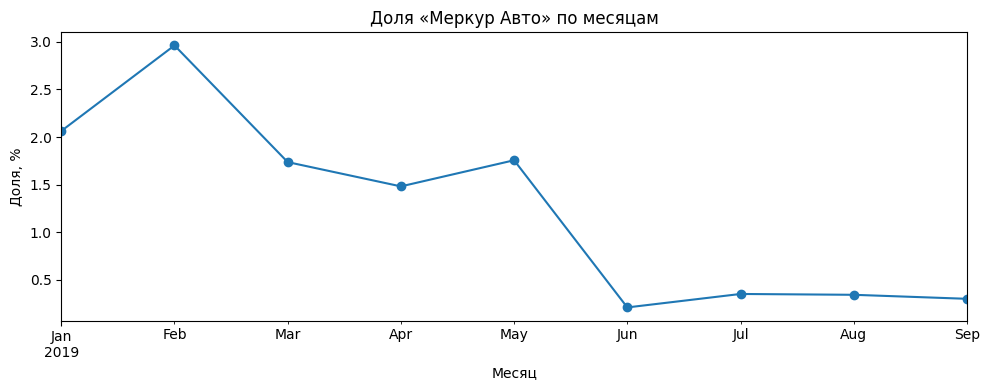

In [48]:
fig, ax = plt.subplots(figsize=(10, 4))
monthly_comp['mercur_share_pct'].plot(marker='o', ax=ax)
ax.set(title='Доля «Меркур Авто» по месяцам', xlabel='Месяц', ylabel='Доля, %')
plt.tight_layout()
plt.show()

## 8. Влияние удаления дубликатов

Сравним объем исходных данных с результатом очистки. Это важно для корректной интерпретации итоговой доли рынка и количества продаж.

In [49]:
raw_qty = parse_numeric(raw['Количество']); raw_revenue = parse_numeric(raw['Продажа, USD'])
comparison = pd.DataFrame({'Исходные строки':[len(raw),raw_qty.sum(),raw_revenue.sum()],
                           'После удаления повторов':[len(clean),clean['quantity'].sum(),clean['total_sales_usd'].sum()]},
                          index=['Строк','Автомобилей (нетто)','Выручка, USD (нетто)'])
comparison['Изменение, %'] = (comparison['После удаления повторов']/comparison['Исходные строки']-1)*100
display(comparison)

,Исходные строки,После удаления повторов,"Изменение, %"
Строк,3.996600e+04,1.778900e+04,-55.489666
Автомобилей (нетто),5.387400e+04,3.159500e+04,-41.353900
"Выручка, USD (нетто)",1.349159e+09,7.199668e+08,-46.635882


## 9. Основные выводы

Итоговые показатели следует интерпретировать с учетом удаления совпадающих строк и отсутствия сведений о прибыли. Анализ позволяет сравнивать продажи и выручку, но не рентабельность компании. Подробные выводы и рекомендации будут представлены в отдельном отчете.